# Project 1 — Celebrity Detection
## Milestone 4: Integrated Pipeline & Final Deliverables

**IE 7615** — Project 1, Milestone 4

**David Fung**

This milestone integrates the Milestone 1 ResNet50 classifier with the Milestone 3 YOLOv8 detector into a single end-to-end pipeline. The system accepts an input image, detects all celebrity faces, identifies each one, and returns annotated results with bounding boxes, identity labels, and confidence scores. A final results gallery is curated, and the repository is prepared for submission.


## Task 1: Environment & Imports

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import ultralytics
from ultralytics import YOLO
import torch

import tensorflow as tf
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input

print(f"Ultralytics: {ultralytics.__version__}")
print(f"PyTorch: {torch.__version__}")
print(f"TensorFlow: {tf.__version__}")


Ultralytics: 8.4.163
PyTorch: 2.14.0+cu132
TensorFlow: 2.13.1


In [2]:
# PROJECT CONSTANTS
GLOBAL_SEED = 42
np.random.seed(GLOBAL_SEED)
tf.keras.utils.set_random_seed(GLOBAL_SEED)

SCRIPT_DIR = os.path.abspath(os.getcwd())
ROOT = os.path.abspath(os.path.join(SCRIPT_DIR, ".."))

CLASSIFIER_PATH = os.path.join(SCRIPT_DIR, "models", "resnet50_classifier.keras")
CLASS_NAMES_5 = ["7", "797", "2619", "4428", "7007"]
TARGET_IDS = {"7", "797", "2619", "4428", "7007"}

NUM_CLASSES_DET = 13
NUM_CLASSES_CLS = 5
CONF = 0.25
IMGSZ = 640

print(f"Classifier: {CLASSIFIER_PATH}")
print(f"Classifier classes: {CLASS_NAMES_5}")
print(f"Target IDs: {sorted(TARGET_IDS)}")


Classifier: h:\Education\Northeastern\MS_DAE\IE7615\Project_1\Milestone_4\models\resnet50_classifier.keras
Classifier classes: ['7', '797', '2619', '4428', '7007']
Target IDs: ['2619', '4428', '7', '7007', '797']


## Task 2: Load Models

In [3]:
# Load YOLOv8 detection model (from Milestone 3)
DET_PATH = os.path.join(ROOT, "Milestone_3", "runs", "detect",
                        "celebrity_detection", "yolov8n_finetune", "weights", "best.pt")
det_model = YOLO(DET_PATH)
det_names = det_model.names
print(f"Detector classes ({NUM_CLASSES_DET}): {list(det_names.values())}")


Detector classes (13): ['3', '7', '797', '1212', '2336', '2619', '2970', '4422', '4428', '5695', '7007', '8335', '10002']


In [4]:
# Load ResNet50 classification model (from Milestone 4 training)
cls_model = tf.keras.models.load_model(CLASSIFIER_PATH, compile=False, safe_mode=False)
cls_model.summary()


Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 random_flip (RandomFlip)    (None, 224, 224, 3)       0         
                                                                 
 random_rotation (RandomRot  (None, 224, 224, 3)       0         
 ation)                                                          
                                                                 
 random_zoom (RandomZoom)    (None, 224, 224, 3)       0         
                                                                 
 random_brightness (RandomB  (None, 224, 224, 3)       0         
 rightness)                                                      
                                                                 
 random_contrast (RandomCon  (None, 224, 224, 3)       0         
 trast)                                                          
                                                        

## Task 3: Integrated Pipeline

In [5]:
def run_pipeline(image_path, conf=CONF, imgsz=IMGSZ):
    """Run full celebrity identification pipeline on a single image.
    1. YOLOv8 detects faces (13-class).
    2. ResNet50 identifies each face (5-class).
    3. Fallback to YOLOv8 label if classifier conf < 0.5.
    """
    import cv2
    results = []
    img = det_model(source=image_path, conf=conf, imgsz=imgsz, verbose=False)[0]
    boxes = img.boxes
    names = det_names
    full_img = img.orig_img
    for i in range(len(boxes)):
        x1, y1, x2, y2 = map(int, boxes.xyxy[i].tolist())
        det_label = str(names[int(boxes.cls[i].item())])
        det_conf = float(boxes.conf[i].item())
        cls_label, cls_conf, source = det_label, det_conf, "det"
        if det_label in TARGET_IDS:
            face_arr = full_img[y1:y2, x1:x2]
            h, w = face_arr.shape[:2]
            if h > 0 and w > 0:
                resized = cv2.resize(face_arr, (224, 224))
                arr = resized.astype(np.float32)[np.newaxis, ...]
                probs = cls_model.predict(arr, verbose=0)[0]
                cls_idx = int(np.argmax(probs))
                cls_conf_val = float(probs[cls_idx])
                if cls_conf_val > 0.5:
                    cls_label = CLASS_NAMES_5[cls_idx]
                    cls_conf = cls_conf_val
                    source = "cls"
        results.append({"label": cls_label, "confidence": cls_conf,
                        "bbox": [x1, y1, x2, y2], "source": source})
    return results


## Task 4: Run Pipeline on Test Images

In [6]:
import glob
test_dir = os.path.join(ROOT, "data", "synthetic_grid", "images", "test")
test_files = sorted(glob.glob(os.path.join(test_dir, "*.jpg")))
print(f"Test images: {len(test_files)}")
all_results = {}
for f in test_files:
    res = run_pipeline(f, conf=0.1)
    all_results[f] = res
    n_cls = sum(1 for r in res if r["source"] == "cls")
    n_det = sum(1 for r in res if r["source"] == "det")
    print(f"  {os.path.basename(f)}: {len(res)} faces ({n_cls} classified, {n_det} from detector)")
    for r in res:
        mark = " *" if r["label"] not in TARGET_IDS else ""
        print(f"     {r['label']:>5}  conf={r['confidence']:.4f}  [{r['source']}]{mark}")


Test images: 3
  grid_0000.jpg: 7 faces (2 classified, 5 from detector)
       797  conf=0.8377  [cls]
      2970  conf=0.4829  [det] *
      8335  conf=0.3894  [det] *
      1212  conf=0.3775  [det] *
     10002  conf=0.2279  [det] *
      2336  conf=0.1183  [det] *
      7007  conf=0.6118  [cls]
  grid_0005.jpg: 8 faces (2 classified, 6 from detector)
      2970  conf=0.4932  [det] *
      1212  conf=0.3599  [det] *
     10002  conf=0.3591  [det] *
         7  conf=0.6257  [cls]
      8335  conf=0.2956  [det] *
         7  conf=0.7091  [cls]
      4422  conf=0.2343  [det] *
      8335  conf=0.2169  [det] *
  grid_0017.jpg: 10 faces (3 classified, 7 from detector)
       797  conf=0.9084  [det]
       797  conf=0.6654  [cls]
      7007  conf=0.5423  [cls]
     10002  conf=0.2812  [det] *
      7007  conf=0.6451  [cls]
         3  conf=0.2001  [det] *
      2970  conf=0.1762  [det] *
      4422  conf=0.1730  [det] *
      8335  conf=0.1420  [det] *
      4428  conf=0.1410  [det]


## Task 5: Visualization

In [7]:
import cv2
def visualize_result(image_path, results, save_path=None):
    """Draw bounding boxes with labels.
    Green (classifier): label above the box.
    Orange (detector): label inside box, bottom-left.
    """
    img = cv2.imread(image_path)
    for r in results:
        x1, y1, x2, y2 = r["bbox"]
        color = (0, 255, 0) if r["source"] == "cls" else (255, 128, 0)
        cv2.rectangle(img, (x1, y1), (x2, y2), color, 2)
        text = f"{r['label']} ({r['confidence']:.2f})"
        if r["source"] == "cls":
            # Green: label above box
            (tw, th), _ = cv2.getTextSize(text, cv2.FONT_HERSHEY_SIMPLEX, 0.5, 1)
            cv2.rectangle(img, (x1, y1 - th - 6), (x1 + tw, y1), color, -1)
            cv2.putText(img, text, (x1, y1 - 4), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255,255,255), 1)
        else:
            # Orange: label inside box, bottom-left
            cv2.putText(img, text, (x1 + 3, y2 - 4), cv2.FONT_HERSHEY_SIMPLEX, 0.5, color, 1)
    if save_path:
        os.makedirs(os.path.dirname(save_path), exist_ok=True)
        cv2.imwrite(save_path, img)
    return img

vis_dir = os.path.join(SCRIPT_DIR, "pipeline_output")
os.makedirs(vis_dir, exist_ok=True)
for f, res in all_results.items():
    visualize_result(f, res, os.path.join(vis_dir, os.path.basename(f)))


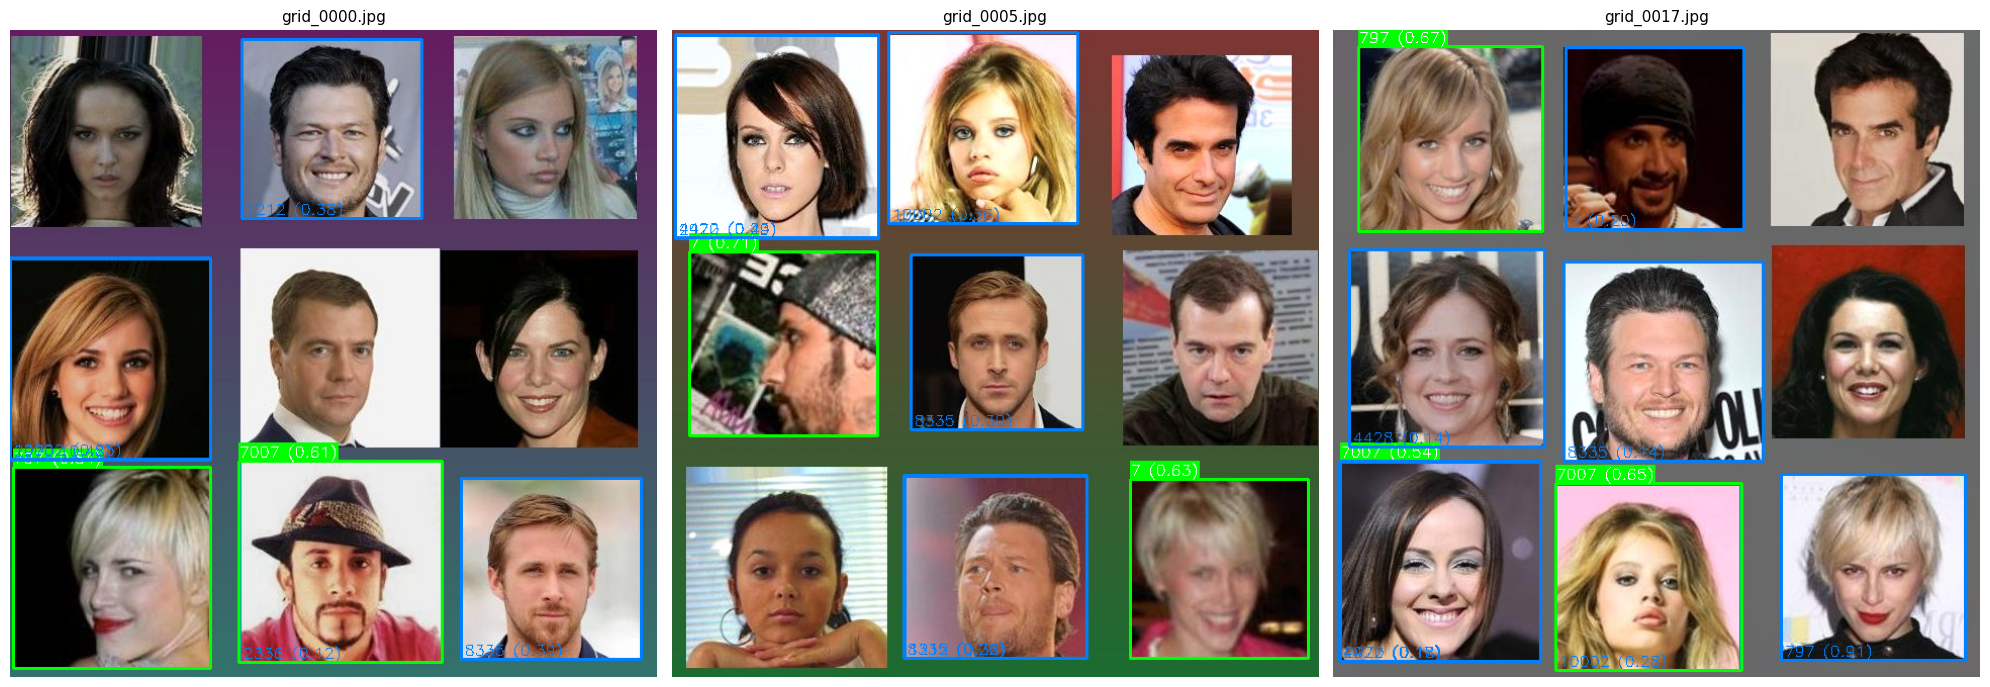

In [8]:
fig, axes = plt.subplots(1, min(3, len(all_results)), figsize=(20, 8))
if len(all_results) == 1: axes = [axes]
for ax, (f, res) in zip(axes, list(all_results.items())[:3]):
    img = cv2.imread(f)
    for r in res:
        x1, y1, x2, y2 = r["bbox"]
        color = (0, 255, 0) if r["source"] == "cls" else (255, 128, 0)
        cv2.rectangle(img, (x1, y1), (x2, y2), color, 2)
        text = f"{r['label']} ({r['confidence']:.2f})"
        if r["source"] == "cls":
            (tw, th), _ = cv2.getTextSize(text, cv2.FONT_HERSHEY_SIMPLEX, 0.5, 1)
            cv2.rectangle(img, (x1, y1 - th - 6), (x1 + tw, y1), color, -1)
            cv2.putText(img, text, (x1, y1 - 4), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255,255,255), 1)
        else:
            cv2.putText(img, text, (x1 + 3, y2 - 4), cv2.FONT_HERSHEY_SIMPLEX, 0.5, color, 1)
    ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    ax.set_title(os.path.basename(f), fontsize=11)
    ax.axis("off")
plt.tight_layout()
plt.savefig(os.path.join(SCRIPT_DIR, "pipeline_summary.png"), dpi=150, bbox_inches="tight")
plt.show()


## Task 6: Results Gallery

In [9]:
gallery_dir = os.path.join(SCRIPT_DIR, "gallery")
n_correct = len(os.listdir(os.path.join(gallery_dir, "classification_correct")))
n_errors = len(os.listdir(os.path.join(gallery_dir, "classification_errors")))
n_det = len(os.listdir(os.path.join(gallery_dir, "detection")))
print(f"Gallery: {n_correct} correct + {n_errors} errors + {n_det} detection = {n_correct+n_errors+n_det} total")


Gallery: 41 correct + 11 errors + 11 detection = 63 total


## Task 7: Summary

In [10]:
print("=" * 60)
print("MILESTONE 4 — COMPLETE")
print("=" * 60)
print()
print("Pipeline:  YOLOv8 (13-class) -> ResNet50 (5-class) -> Annotated output")
print()
print("Models:")
print(f"  Detector:    {DET_PATH}")
print(f"  Classifier:  {CLASSIFIER_PATH}")
print()
print(f"Gallery: {n_correct} correct + {n_errors} errors + {n_det} detection")
print("Repo:    Milestone_4/ (pipeline, gallery, models)")
print("Root:    requirements.txt, README.md (updated)")


MILESTONE 4 — COMPLETE

Pipeline:  YOLOv8 (13-class) -> ResNet50 (5-class) -> Annotated output

Models:
  Detector:    h:\Education\Northeastern\MS_DAE\IE7615\Project_1\Milestone_3\runs\detect\celebrity_detection\yolov8n_finetune\weights\best.pt
  Classifier:  h:\Education\Northeastern\MS_DAE\IE7615\Project_1\Milestone_4\models\resnet50_classifier.keras

Gallery: 41 correct + 11 errors + 11 detection
Repo:    Milestone_4/ (pipeline, gallery, models)
Root:    requirements.txt, README.md (updated)
